# Synthetic example: Figs. 1, 2 and 3

Regression problem $Y=f(X)+\varepsilon$ with $X\sim U(0,1)$, $f(x)=5x+5x^4-9x^2$ and a perfect model, so the distribution of the scores $|Y-f(X)|$ is known. Request: $C^\mathrm{nom}=C^\mathrm{min}=0.9$, $1-\alpha=0.95$. Runs in about a minute.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import reliable_conformal_prediction as rcp

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import cp_plot as cpl  # noqa: E402
import cp_tools as ct  # noqa: E402

FIG = HERE / "figures"
warnings.simplefilter("ignore", rcp.InfeasibleRequestWarning)  # below the minimum size, the index is N_cal + 1 (trivial set)

C_NOM = C_MIN = 0.9  # nominal coverage (standard procedure) and requested minimum coverage (proposed procedure)
CONF = 0.95  # 1 - alpha
CONF_LEVELS = (0.9, 0.95, 0.99)
ZOO = ct.noise_zoo(c_ref=C_MIN)  # noise families scaled so that the true threshold is t* = 1
LAWS = {k: ct.FoldedScoreLaw(v) for k, v in ZOO.items()}
LBL = ct.FAMILY_LABELS
N = 100
m_std, m_new = rcp.get_index_standard(N, C_NOM), rcp.get_index(N, C_MIN, CONF)  # 91 and 96
# the package functions take one calibration size at a time
index_standard, index_new = np.vectorize(rcp.get_index_standard), np.vectorize(rcp.get_index)
confidence = np.vectorize(rcp.get_confidence)

## Fig. 1: one calibration set, and the distribution of the realised coverage

In [2]:
dgp = ct.SyntheticDGP(noise=ZOO["gaussian"])
law = LAWS["gaussian"]
t_star = float(law.ppf(C_MIN))
rng = np.random.default_rng(ct.seed_for("A1 calibration set 1"))
x_cal, y_cal = dgp.sample(rng, N)
s_cal = dgp.score(x_cal, y_cal)
thr = {"std": np.sort(s_cal)[m_std - 1], "new": rcp.get_threshold(s_cal, C_MIN, CONF)}

R_MC = 100_000  # Monte Carlo check of the beta laws
mc = ct.score_mc(law, N, {"std": m_std, "new": m_new}, R_MC, "A1 score-level Monte Carlo")
cov_mc = {k: law.cdf(v) for k, v in mc.items()}

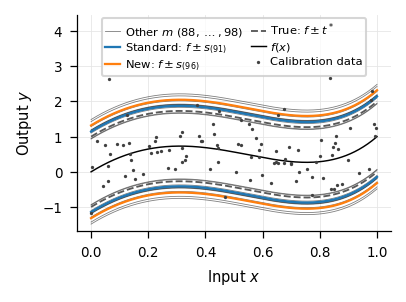

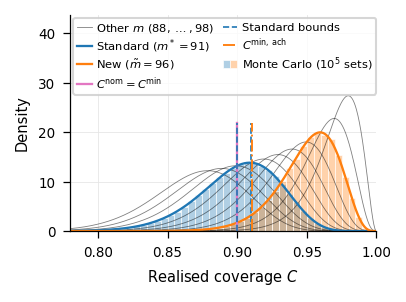

In [3]:
xx = np.linspace(0, 1, 400)
cc = np.linspace(0.78, 1.0, 600)
SUB2 = (cpl.TEXT_WIDTH * 0.48, 1.9)
LEG2 = dict(fontsize=5.5, borderaxespad=0.3, borderpad=0.3, handlelength=1.3, handletextpad=0.4, ncol=2, columnspacing=0.7,
            labelspacing=0.25)  # legends in two columns, inside half-width panels
others = np.arange(m_std - 3, m_new + 3)  # thin lines for other indices
srt = np.sort(s_cal)
OTHERS = f"Other $m$ (${others[0]},\\dots,{others[-1]}$)"
SHORT = {"std": "Standard", "new": "New"}
LAB = {"std": f"Standard ($m^*={m_std}$)", "new": f"New ($\\tilde m={m_new}$)"}
with cpl.style():
    # Fig. 1a: calibration data and prediction intervals
    fig, a = plt.subplots(figsize=SUB2, layout="constrained")
    for i, m in enumerate(others):
        for sign in (1, -1):
            a.plot(xx, dgp.f(xx) + sign * srt[m - 1], color="k", lw=0.4, alpha=0.5,
                   label=OTHERS if (i == 0 and sign == 1) else None)
    for k, m in [("std", m_std), ("new", m_new)]:
        for sign in (1, -1):
            a.plot(xx, dgp.f(xx) + sign * thr[k], color=cpl.COL[k], lw=1.1,
                   label=f"{SHORT[k]}: $f\\pm s_{{({m})}}$" if sign == 1 else None)
    for sign in (1, -1):
        a.plot(xx, dgp.f(xx) + sign * t_star, color=cpl.COL["oracle"], ls="--", lw=0.9,
               label="True: $f\\pm t^*$" if sign == 1 else None)
    a.plot(xx, dgp.f(xx), color="k", lw=0.7, label="$f(x)$")
    a.scatter(x_cal, y_cal, s=2.5, color=cpl.COL["cal"], lw=0, zorder=3, label="Calibration data")
    s_top = srt[others[-1] - 1]
    lo, hi = min(y_cal.min(), (dgp.f(xx) - s_top).min()), (dgp.f(xx) + s_top).max()
    a.set(xlabel="Input $x$", ylabel="Output $y$", ylim=(lo - 0.05 * (hi - lo), hi + 0.5 * (hi - lo)))
    a.legend(loc="upper center", **LEG2)
    cpl.savefig(fig, "fig_synthetic_intervals", figdir=FIG)
    plt.show()

    # Fig. 1b: exact beta laws of the realised coverage (lines) and Monte Carlo (bars)
    fig, b = plt.subplots(figsize=SUB2, layout="constrained")
    b.set_axisbelow(True)
    MC_BARS = {k: dict(color=to_rgba(cpl.COL[k], 0.35), edgecolor="white", linewidth=0.3) for k in ("std", "new")}
    for i, m in enumerate(others):
        b.plot(cc, ct.coverage_law(N, m).pdf(cc), color="k", lw=0.4, alpha=0.5, label=OTHERS if i == 0 else None)
    for k, m in [("std", m_std), ("new", m_new)]:
        b.hist(cov_mc[k], bins=np.linspace(0.78, 1, 45), density=True, **MC_BARS[k])
        b.plot(cc, ct.coverage_law(N, m).pdf(cc), color=cpl.COL[k], lw=1.1, label=LAB[k])
    b.axvline(C_MIN, ymax=0.5, color=cpl.COL["cmin"], lw=1.1, label="$C^{\\mathrm{nom}}=C^{\\mathrm{min}}$")
    for i, c_b in enumerate((C_NOM, C_NOM + 1 / (N + 1))):  # bounds of Eq. (2)
        b.axvline(c_b, ymax=0.5, color=cpl.COL["std"], ls="--", lw=0.8,
                  label="Standard bounds" if i == 0 else None)
    b.axvline(rcp.get_mincov(N, CONF, min_cov=C_MIN), ymax=0.5, color=cpl.COL["new"], ls="-.", lw=0.9,
              label="$C^{\\mathrm{min,\\,ach}}$")
    handles, labels = b.get_legend_handles_labels()
    mc_proxy = tuple(Patch(fc=v["color"], ec=v["edgecolor"], lw=v["linewidth"]) for v in MC_BARS.values())
    peak = max(ct.coverage_law(N, m).pdf(cc).max() for m in others)
    b.set(xlabel="Realised coverage $C$", ylabel="Density", xlim=(0.78, 1.0), ylim=(0, 1.6 * peak))
    b.legend(handles + [mc_proxy], labels + ["Monte Carlo ($10^5$ sets)"], loc="upper left",
             handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, **LEG2)
    cpl.savefig(fig, "fig_synthetic_coverage", figdir=FIG)
    plt.show()

## Fig. 2: (a) probability of undercoverage (exact, from the beta law of $C$) and (b) quantile levels of both procedures, against $N_\mathrm{cal}$

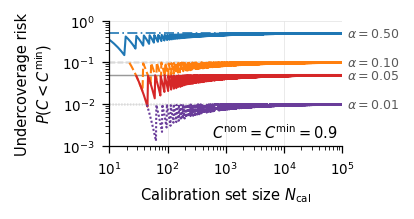

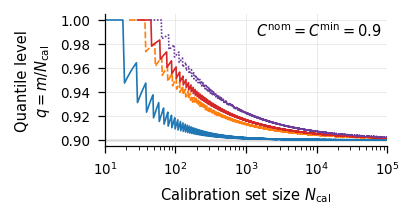

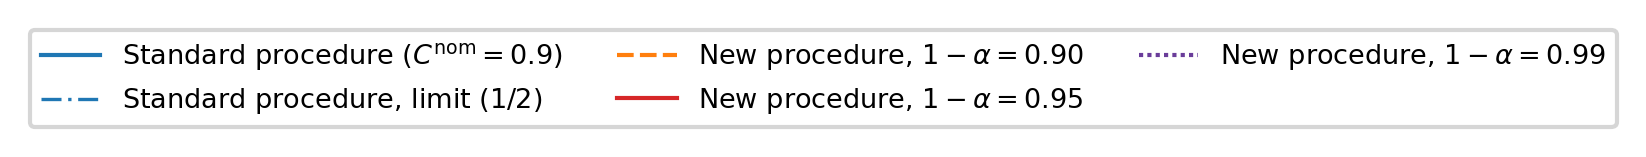

In [4]:
N_ALL = np.arange(10, 100_001)
m_all = {"std": index_standard(N_ALL, C_NOM), **{conf: index_new(N_ALL, C_MIN, conf) for conf in CONF_LEVELS}}
risk_all = {"std": 1 - confidence(N_ALL, m_all["std"], C_MIN)}
q_std, q_new = m_all["std"] / N_ALL, {}  # quantile levels q = m / N_cal
for conf in CONF_LEVELS:
    m = m_all[conf]
    risk_all[conf] = np.where(m <= N_ALL, 1 - confidence(N_ALL, m, C_MIN), np.nan)  # NaN below N_min
    q_new[conf] = np.where(m <= N_ALL, m / N_ALL, np.nan)

SUB_F2 = (cpl.TEXT_WIDTH * 0.49, 1.35)
LAB_F2 = {"std": f"{cpl.LABEL['std']} ($C^{{\\mathrm{{nom}}}}=0.9$)",
          "lim": "Standard procedure, limit ($1/2$)",
          **{conf: f"{cpl.LABEL['new']}, $1-\\alpha={conf:.2f}$" for conf in CONF_LEVELS}}
LS_LIM = (0, (6, 2, 1, 2))
with cpl.style():
    # Fig. 2a: probability of undercoverage
    fig, a = plt.subplots(figsize=SUB_F2, layout="constrained")
    a.plot(N_ALL, risk_all["std"], color=cpl.COL["std"], lw=1.0)
    a.axhline(0.5, color=cpl.COL["std"], ls=LS_LIM, lw=0.8)
    ALPHA_LAB = dict(transform=a.get_yaxis_transform(), color="0.35", ha="left", va="center", fontsize=6)  # right of the axes
    a.text(1.02, 0.5, "$\\alpha=0.50$", **ALPHA_LAB)
    for conf in CONF_LEVELS:
        a.plot(N_ALL, risk_all[conf], color=cpl.CONF_COL[conf], ls=cpl.LS_CONF[conf], lw=1.0)
        a.axhline(1 - conf, color="0.6", ls=cpl.LS_CONF[conf], lw=0.7, zorder=0)
        a.text(1.02, 1 - conf, f"$\\alpha={1 - conf:.2f}$", **ALPHA_LAB)
    a.text(0.98, 0.04, "$C^{\\mathrm{nom}}=C^{\\mathrm{min}}=0.9$", transform=a.transAxes, ha="right", va="bottom")
    a.set(xscale="log", yscale="log", xlim=(10, 1e5), ylim=(1e-3, 1), xlabel=cpl.XLAB_N,
          ylabel="Undercoverage risk\n$P(C<C^{\\mathrm{min}})$")
    cpl.savefig(fig, "fig_risk_vs_N", figdir=FIG)
    plt.show()

    # Fig. 2b: quantile levels of the thresholds
    fig, b = plt.subplots(figsize=SUB_F2, layout="constrained")
    b.axhline(C_MIN, color="0.6", lw=0.7, zorder=0)
    b.plot(N_ALL, q_std, color=cpl.COL["std"], lw=0.8)
    for conf in CONF_LEVELS:
        b.plot(N_ALL, q_new[conf], color=cpl.CONF_COL[conf], ls=cpl.LS_CONF[conf], lw=0.8)
    b.text(0.98, 0.95, "$C^{\\mathrm{nom}}=C^{\\mathrm{min}}=0.9$", transform=b.transAxes, ha="right", va="top")
    b.set(xscale="log", xlim=(10, 1e5), ylim=(0.895, 1.005), yticks=np.arange(0.90, 1.001, 0.02), xlabel=cpl.XLAB_N,
          ylabel="Quantile level\n$q=m/N_{\\mathrm{cal}}$")
    cpl.savefig(fig, "fig_quantile_levels", figdir=FIG)
    plt.show()

    # one legend for both subfigures
    h = [Line2D([], [], color=cpl.COL["std"], lw=1.0), Line2D([], [], color=cpl.COL["std"], ls=LS_LIM, lw=0.8)]
    h += [Line2D([], [], color=cpl.CONF_COL[c], ls=cpl.LS_CONF[c], lw=1.0) for c in CONF_LEVELS]
    fig = plt.figure(figsize=(cpl.TEXT_WIDTH, 0.32))
    fig.legend(h, [LAB_F2[k] for k in ("std", "lim", *CONF_LEVELS)], loc="center", ncol=3)
    cpl.savefig(fig, "fig_risk_legend", figdir=FIG)
    plt.close(fig)
display(Image(FIG / "fig_risk_legend.png", width=810))  # the inline backend does not draw a figure without axes

## Fig. 3a: half-width relative to the true one against $N_\mathrm{cal}$, for four noise distributions

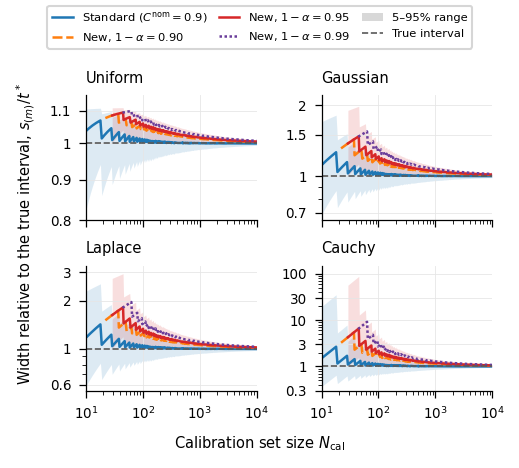

In [5]:
P_BAND = (0.05, 0.5, 0.95)
N_W = np.unique(np.concatenate([np.round(np.logspace(1, 4, 300)).astype(int), [29, N, 500, 1000]]))
frames = []
for fam, lw in LAWS.items():
    for proc, conf in [("std", np.nan)] + [("new", c) for c in CONF_LEVELS]:
        m = index_standard(N_W, C_NOM) if proc == "std" else index_new(N_W, C_MIN, conf)
        q = {f"R_p{round(100 * p):02d}": ct.threshold_quantile(lw, N_W, m, p) / t_star for p in P_BAND}
        frames.append(pd.DataFrame({"family": fam, "procedure": proc, "conf": conf, "N": N_W, "m": m, **q}))
width = pd.concat(frames, ignore_index=True).replace([np.inf, -np.inf], np.nan)  # NaN: infeasible

FAMS_W = ("uniform", "gaussian", "laplace", "cauchy")
Y_W = {"uniform": ((0.8, 1.15), [0.8, 0.9, 1, 1.1]), "gaussian": ((0.65, 2.2), [0.7, 1, 1.5, 2]),
       "laplace": ((0.55, 3.3), [0.6, 1, 2, 3]), "cauchy": ((0.3, 150), [0.3, 1, 3, 10, 30, 100])}
SERIES_W = [("std", np.nan, cpl.COL["std"], "-", "Standard ($C^{\\mathrm{nom}}=0.9$)")]
SERIES_W += [("new", c, cpl.CONF_COL[c], cpl.LS_CONF[c], f"New, $1-\\alpha={c:.2f}$") for c in CONF_LEVELS]
with cpl.style():
    fig, axes = plt.subplots(2, 2, figsize=(cpl.TEXT_WIDTH * 0.62, 3.0), sharex=True, layout="constrained")
    for a, fam in zip(axes.flat, FAMS_W):
        d = width[width.family == fam]
        for proc, conf, col, ls, _ in SERIES_W:
            e = d[(d.procedure == proc) & ((d.conf == conf) if proc == "new" else d.conf.isna())]
            if proc == "std" or conf == CONF:  # bands only for the standard procedure and the proposed one at 0.95
                a.fill_between(e.N, e.R_p05, e.R_p95, color=col, alpha=0.15, lw=0)
            a.plot(e.N, e.R_p50, color=col, ls=ls, lw=1.2)
        a.axhline(1, color=cpl.COL["oracle"], ls="--", lw=0.8)
        (lo, hi), ticks = Y_W[fam]
        a.set(xscale="log", yscale="log", xlim=(10, 1e4), ylim=(lo, hi), title=LBL[fam])
        a.set_yticks(ticks, [f"{t:g}" for t in ticks])
        a.yaxis.set_minor_formatter(plt.NullFormatter())
    fig.supxlabel(cpl.XLAB_N)
    fig.supylabel("Width relative to the true interval, $s_{(m)}/t^*$")
    handles = [Line2D([], [], color=col, ls=ls, lw=1.2, label=lab) for _, _, col, ls, lab in SERIES_W]
    handles += [Patch(fc="0.5", alpha=0.3, lw=0, label="5–95% range"),
                Line2D([], [], color=cpl.COL["oracle"], ls="--", lw=0.8, label="True interval")]
    fig.legend(handles=handles, loc="outside upper center", ncol=3, fontsize=5.5, columnspacing=1.0, handlelength=1.8)
    cpl.savefig(fig, "fig_width_vs_N", figdir=FIG)
    plt.show()

## Fig. 3b: ratio of the half-widths of both procedures on the same calibration set ($N_\mathrm{cal}=100$)

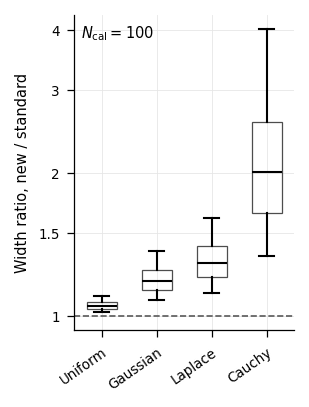

In [6]:
pair = {fam: ct.score_mc(LAWS[fam], N, {"std": m_std, "new": m_new}, R_MC, f"A3 paired {fam}") for fam in FAMS_W}
ratio_pair = {fam: v["new"] / v["std"] for fam, v in pair.items()}
with cpl.style():
    fig, a = plt.subplots(figsize=(cpl.TEXT_WIDTH * 0.36, 2.6), layout="constrained")
    fams = list(FAMS_W)
    bp = a.boxplot([ratio_pair[f] for f in fams], whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True,
                   medianprops=dict(color="k", lw=1))
    for patch in bp["boxes"]:
        patch.set(facecolor="none", edgecolor="0.3", lw=0.6)
    a.axhline(1, color=cpl.COL["oracle"], ls="--", lw=0.8)  # equal widths
    a.set_xticks(range(1, len(fams) + 1), [LBL[f] for f in fams], rotation=35, ha="right", rotation_mode="anchor")
    a.set(yscale="log", ylabel="Width ratio, new / standard")
    a.set_yticks([1, 1.5, 2, 3, 4], ["1", "1.5", "2", "3", "4"])
    a.yaxis.set_minor_formatter(plt.NullFormatter())
    a.text(0.03, 0.97, f"$N_{{\\mathrm{{cal}}}}={N}$", transform=a.transAxes, va="top", ha="left")
    cpl.savefig(fig, "fig_width_ratio", figdir=FIG)
    plt.show()